# Exercise 1 - Multi-Layer Perceptron classifier (CIFAR-10)

**PUSL3123 AI and Machine Learning - Assessment 1**

**Aim:** build, train and evaluate a Multi-Layer Perceptron (MLP) with three trainable layers on CIFAR-10 using PyTorch.

**Contents**
1. Setup and configuration
2. Data preparation (standard partitions, validation split, class distribution)
3. Helper functions (training, evaluation, plotting)
4. Model: three-layer MLP
5. Training
6. Training and validation curves
7. Final evaluation (train / validation / test)
8. Save results

**How to run:** `pip install -r requirements.txt`, then *Run All*. Set the environment variable `QUICK_RUN=1` for a 2-epoch smoke test. The dataset downloads automatically into `data/`.

## 1. Setup and configuration

All four notebooks share the same configuration (seed, validation size, batch size, learning rate, epochs) so that results are directly comparable.

In [1]:
import os, json, time, random

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision

# ---------------------------------------------------------------------------
# Configuration -- identical in all four notebooks so that results are comparable
# ---------------------------------------------------------------------------
SEED          = 42        # default run seed: weight initialisation, augmentation and batch shuffling
SPLIT_SEED    = 42        # train/validation split: identical for every experiment and every run
SEEDS         = (42, 43, 44)   # run seeds for the multi-seed experiments (Exercises 3 and 4)
VAL_SIZE      = 5_000     # validation images held out from the 50,000 training images
BATCH_SIZE    = 128
LEARNING_RATE = 1e-3
EPOCHS        = 2 if os.environ.get("QUICK_RUN") else 30   # set QUICK_RUN=1 for a 2-epoch smoke test
DATA_DIR      = "data"
RESULTS_DIR   = "results"
FIG_DIR       = os.path.join(RESULTS_DIR, "figures")
DEVICE        = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASSES = ("aeroplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")

os.makedirs(FIG_DIR, exist_ok=True)

def set_seed(seed=SEED):
    """Seed one run: weight initialisation plus dropout and augmentation randomness."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only")
print(f"Epochs: {EPOCHS} | batch size: {BATCH_SIZE} | learning rate: {LEARNING_RATE} | seed: {SEED}")

PyTorch 2.5.1+cu121 | torchvision 0.20.1+cu121
Device: cuda | NVIDIA GeForce RTX 4050 Laptop GPU
Epochs: 30 | batch size: 128 | learning rate: 0.001 | seed: 42


## 2. Data preparation

* CIFAR-10 is loaded with `torchvision.datasets.CIFAR10` using the **standard partitions**: 50,000 training images and 10,000 test images.
* The test partition is kept completely separate: it is **not** used for training, hyper-parameter tuning or model selection.
* A **validation set of 5,000 images is held out from the 50,000 training images** with a fixed seed (`SPLIT_SEED`), leaving 45,000 images for training. The same split is used in every experiment.
* Images are decoded once into a single `uint8` tensor that lives on `DEVICE` for the rest of the notebook. Each minibatch is normalised with the CIFAR-10 mean and standard deviation on the fly (see `GPULoader` below), which avoids the per-sample CPU transforms and `DataLoader` worker overhead that otherwise dominate training time. No data augmentation is used in this exercise.

In [2]:
# Per-channel mean / std of the CIFAR-10 training images
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
MEAN_T = torch.tensor(MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_T  = torch.tensor(STD,  device=DEVICE).view(1, 3, 1, 1)

class GPULoader:
    """Minibatch iterator over images held entirely on DEVICE as a single uint8 tensor.

    Keeping a whole partition resident on DEVICE and normalising per batch -- instead of per-sample
    disk reads and CPU transforms behind a `DataLoader` -- removes the CPU bottleneck in data loading.
    Shuffling uses a seeded CPU generator so that the epoch order is reproducible; `augment`, if given,
    is applied to the already-normalised batch on the GPU (used from Exercise 3 onwards).
    """
    def __init__(self, images, targets, batch_size, shuffle, seed=SEED, augment=None):
        self.images, self.targets = images, targets   # uint8 (N,3,32,32) / int64 (N,), both on DEVICE
        self.batch_size, self.shuffle, self.augment = batch_size, shuffle, augment
        self.generator = torch.Generator().manual_seed(seed) if shuffle else None

    def __iter__(self):
        n = self.images.size(0)
        order = torch.randperm(n, generator=self.generator) if self.shuffle else torch.arange(n)
        order = order.to(self.images.device)
        for start in range(0, n, self.batch_size):
            idx = order[start:start + self.batch_size]
            x = (self.images[idx].float() / 255 - MEAN_T) / STD_T
            if self.augment is not None:
                x = self.augment(x)
            yield x, self.targets[idx]

    def __len__(self):
        return (self.images.size(0) + self.batch_size - 1) // self.batch_size


_partitions = {}   # decoded tensors, cached so that repeated build_data calls never reload from disk

def load_partitions():
    """Decode CIFAR-10 into DEVICE memory once per kernel and apply the fixed train/validation split.
    Standard partitions (50,000 train / 10,000 test); VAL_SIZE images are held out from the training
    images using SPLIT_SEED, so the split is identical for every experiment and every run seed."""
    if not _partitions:
        train_raw = torchvision.datasets.CIFAR10(DATA_DIR, train=True,  download=True)
        test_raw  = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)

        def as_device_tensors(ds):
            images = torch.from_numpy(ds.data).permute(0, 3, 1, 2).contiguous().to(DEVICE)  # (N,3,32,32) uint8
            targets = torch.tensor(ds.targets, dtype=torch.long, device=DEVICE)
            return images, targets

        train_images, train_targets = as_device_tensors(train_raw)
        test_images,  test_targets  = as_device_tensors(test_raw)

        perm = torch.randperm(len(train_raw), generator=torch.Generator().manual_seed(SPLIT_SEED))
        val_idx, train_idx = perm[:VAL_SIZE].to(DEVICE), perm[VAL_SIZE:].to(DEVICE)
        _partitions.update(train=(train_images[train_idx], train_targets[train_idx]),
                           val=(train_images[val_idx], train_targets[val_idx]),
                           test=(test_images, test_targets))
    return _partitions


def build_data(augment=None, seed=SEED):
    """Loaders for the fixed partitions. `seed` only controls the shuffling of the training batches (the
    split always uses SPLIT_SEED). `augment` is an optional GPU-side callable applied only to the training
    batches (Exercise 3 onwards). The test set is never used for training or model selection."""
    partitions = load_partitions()

    def loader(name, shuffle=False, augment=None):
        images, targets = partitions[name]
        return GPULoader(images, targets, BATCH_SIZE, shuffle=shuffle, seed=seed, augment=augment)

    return {
        "train":       loader("train", shuffle=True, augment=augment),  # used for training
        "train_clean": loader("train"),                                 # same images, no augmentation
        "val":         loader("val"),                                   # validation (model selection)
        "test":        loader("test"),                                  # final reporting only
    }

loaders = build_data()
print("Images per partition:", {k: v.images.shape[0] for k, v in loaders.items()})

Files already downloaded and verified


Files already downloaded and verified


Images per partition: {'train': 45000, 'train_clean': 45000, 'val': 5000, 'test': 10000}


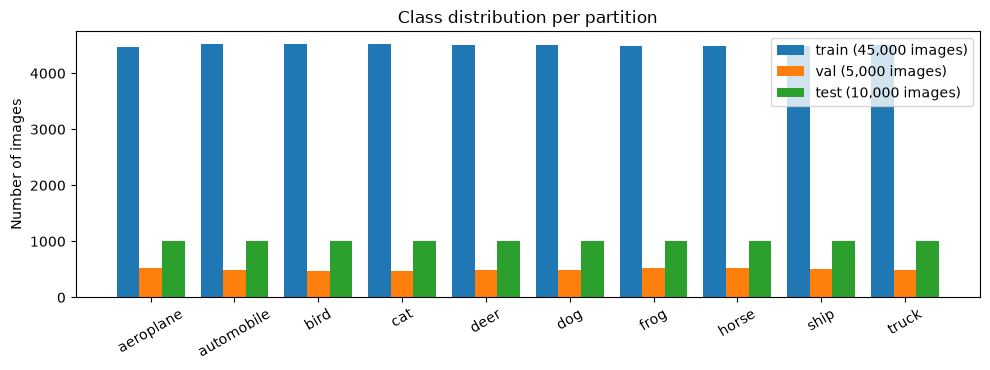

Files already downloaded and verified


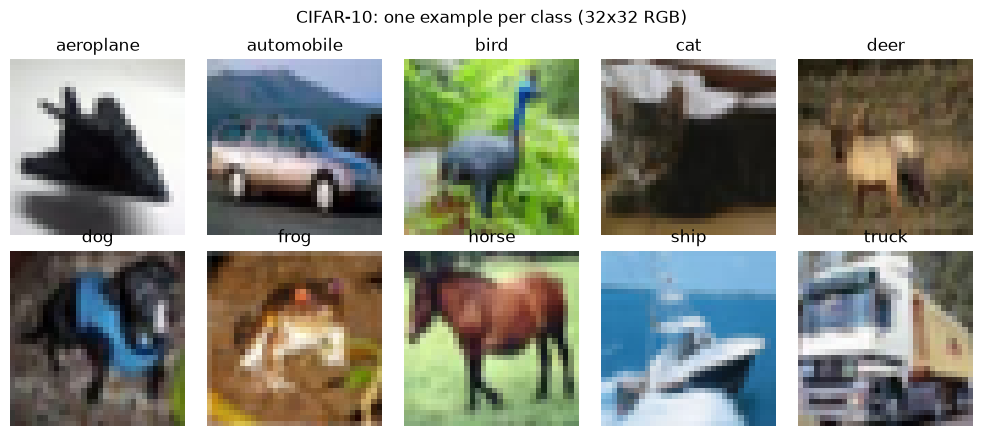

In [3]:
def class_counts(loader):
    """Number of images per class held by a GPULoader partition."""
    return np.bincount(loader.targets.cpu().numpy(), minlength=len(CLASSES))

counts = {name: class_counts(loaders[name]) for name in ("train", "val", "test")}

x, w = np.arange(len(CLASSES)), 0.27
plt.figure(figsize=(10, 3.8))
for i, (name, c) in enumerate(counts.items()):
    plt.bar(x + (i - 1) * w, c, w, label=f"{name} ({c.sum():,} images)")
plt.xticks(x, CLASSES, rotation=30)
plt.ylabel("Number of images")
plt.title("Class distribution per partition")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "class_distribution.png"), dpi=200)
plt.show()

# One example image per class
raw = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
raw_targets = np.array(raw.targets)
fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(raw[int(np.where(raw_targets == c)[0][0])][0])
    ax.set_title(CLASSES[c])
    ax.axis("off")
fig.suptitle("CIFAR-10: one example per class (32x32 RGB)")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "cifar10_samples.png"), dpi=200)
plt.show()

## 3. Helper functions

* `fit` trains with **Adam** and **cross-entropy loss**, records loss and accuracy per epoch, and restores the weights of the epoch with the best **validation** accuracy.
* `evaluate` / `final_evaluation` compute loss and accuracy; the test set is only used in `final_evaluation`, after training has finished.
* Plotting and saving utilities produce the figures and JSON results used in the report.

In [4]:
def count_parameters(model):
    """Number of trainable parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, loader):
    """Mean cross-entropy loss and accuracy of `model` on `loader` (eval mode: no dropout)."""
    criterion = nn.CrossEntropyLoss()
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        total_loss += criterion(out, y).item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += y.size(0)
    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, epochs=EPOCHS, lr=LEARNING_RATE, weight_decay=0.0, verbose=True):
    """Train with Adam + cross-entropy. After every epoch the model is scored on the validation set; the
    weights of the epoch with the highest validation accuracy are restored at the end (model selection
    uses validation data only -- never the test set). Running loss/accuracy are accumulated as GPU
    tensors and only moved to the CPU once per epoch (`.item()`), instead of after every batch, since a
    host-device sync on every step would otherwise stall the GPU pipeline."""
    criterion = nn.CrossEntropyLoss()
    optimiser = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc, best_epoch, best_state = -1.0, 0, None
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        run_loss = torch.zeros((), device=DEVICE)
        run_correct = torch.zeros((), device=DEVICE)
        seen = 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimiser.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimiser.step()
            run_loss += loss.detach() * y.size(0)
            run_correct += (out.argmax(1) == y).sum()
            seen += y.size(0)

        history["train_loss"].append((run_loss / seen).item())
        history["train_acc"].append((run_correct / seen).item())
        val_loss, val_acc = evaluate(model, val_loader)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc, best_epoch = val_acc, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

        if verbose:
            print(f"Epoch {epoch:02d}/{epochs} | train loss {history['train_loss'][-1]:.4f} "
                  f"acc {history['train_acc'][-1]:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}")

    model.load_state_dict(best_state)
    return history, best_epoch, time.time() - start

def final_evaluation(model, loaders):
    """Loss / accuracy on the clean training images, the validation set and the test set."""
    result = {}
    for key, loader_name in (("train", "train_clean"), ("val", "val"), ("test", "test")):
        loss, acc = evaluate(model, loaders[loader_name])
        result[f"{key}_loss"], result[f"{key}_acc"] = loss, acc
    return result

def print_final(final):
    print(f"{'Partition':<12}{'Loss':>8}{'Accuracy':>11}")
    for part in ("train", "val", "test"):
        print(f"{part:<12}{final[part + '_loss']:>8.4f}{final[part + '_acc'] * 100:>10.2f}%")
    gap = (final["train_acc"] - final["test_acc"]) * 100
    print(f"Generalisation gap (train - test accuracy): {gap:.2f} percentage points")

def plot_history(history, best_epoch, title, filename):
    """Training vs validation loss (left) and accuracy (right)."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(epochs, history["train_loss"], label="Training loss")
    axes[0].plot(epochs, history["val_loss"], label="Validation loss")
    axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
    axes[1].plot(epochs, history["train_acc"], label="Training accuracy")
    axes[1].plot(epochs, history["val_acc"], label="Validation accuracy")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
    for ax in axes:
        ax.axvline(best_epoch, ls="--", c="grey", label=f"Selected epoch ({best_epoch})")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, filename), dpi=200)
    plt.show()

@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, labels = [], []
    for x, y in loader:
        preds.append(model(x.to(DEVICE)).argmax(1).cpu())
        labels.append(y.cpu())
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()

def plot_confusion_matrix(model, loader, title, filename):
    """Confusion matrix (rows = true class, columns = predicted class). Returns the count matrix."""
    preds, labels = predict(model, loader)
    cm = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
    np.add.at(cm, (labels, preds), 1)
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set(xticks=range(len(CLASSES)), yticks=range(len(CLASSES)), xlabel="Predicted class",
           ylabel="True class", title=title)
    ax.set_xticklabels(CLASSES, rotation=45, ha="right")
    ax.set_yticklabels(CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, filename), dpi=200)
    plt.show()
    return cm

def save_results(name, payload):
    """Write results to results/<name>.json (used for the tables and graphs in the report)."""
    path = os.path.join(RESULTS_DIR, f"{name}.json")
    with open(path, "w") as f:
        json.dump(payload, f, indent=2)
    print("Saved", path)

## 4. Model: three-layer MLP

The MLP flattens each 3x32x32 image into 3,072 values and passes it through three fully connected (trainable) layers:

| Layer | Shape | Activation |
|---|---|---|
| Linear 1 | 3072 -> 1024 | ReLU |
| Linear 2 | 1024 -> 512 | ReLU |
| Linear 3 | 512 -> 10 | none (logits) |

**Design choices**
* **ReLU** activations: cheap, avoid vanishing gradients in the hidden layers.
* **Cross-entropy loss**: the standard loss for multi-class classification (it applies softmax internally, so the last layer outputs raw logits).
* **Adam** (learning rate 1e-3): adaptive optimiser that works well with little tuning.
* No dropout or augmentation here, so this MLP is a plain baseline.

In [5]:
class MLP(nn.Module):
    """Multi-Layer Perceptron with three trainable (fully connected) layers: 3072 -> 1024 -> 512 -> 10."""
    def __init__(self, hidden1=1024, hidden2=512, num_classes=len(CLASSES)):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                       # 3 x 32 x 32 image -> vector of 3072 values
            nn.Linear(3 * 32 * 32, hidden1),    # trainable layer 1
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),        # trainable layer 2
            nn.ReLU(),
            nn.Linear(hidden2, num_classes),    # trainable layer 3 (class scores / logits)
        )

    def forward(self, x):
        return self.net(x)

set_seed(SEED)
model = MLP().to(DEVICE)
print(model)
print()
for name, p in model.named_parameters():
    print(f"{name:14s} {str(tuple(p.shape)):16s} {p.numel():>10,}")
n_params = count_parameters(model)
print(f"\nTotal trainable parameters: {n_params:,}")

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=1024, bias=True)
    (2): ReLU()
    (3): Linear(in_features=1024, out_features=512, bias=True)
    (4): ReLU()
    (5): Linear(in_features=512, out_features=10, bias=True)
  )
)

net.1.weight   (1024, 3072)      3,145,728
net.1.bias     (1024,)               1,024
net.3.weight   (512, 1024)         524,288
net.3.bias     (512,)                  512
net.5.weight   (10, 512)             5,120
net.5.bias     (10,)                    10

Total trainable parameters: 3,676,682


## 5. Training

In [6]:
history, best_epoch, train_seconds = fit(model, loaders["train"], loaders["val"])
print(f"\nSelected epoch {best_epoch} (highest validation accuracy) | training time {train_seconds:.0f} s")

Epoch 01/30 | train loss 1.6659 acc 0.4115 | val loss 1.5515 acc 0.4524


Epoch 02/30 | train loss 1.4587 acc 0.4867 | val loss 1.4490 acc 0.4956


Epoch 03/30 | train loss 1.3447 acc 0.5254 | val loss 1.4331 acc 0.5006


Epoch 04/30 | train loss 1.2540 acc 0.5557 | val loss 1.4094 acc 0.5146


Epoch 05/30 | train loss 1.1770 acc 0.5810 | val loss 1.3714 acc 0.5340


Epoch 06/30 | train loss 1.0958 acc 0.6108 | val loss 1.4283 acc 0.5236


... (20 outputs left out)

Epoch 27/30 | train loss 0.3006 acc 0.8943 | val loss 3.0194 acc 0.5370


Epoch 28/30 | train loss 0.2847 acc 0.8996 | val loss 3.0812 acc 0.5306


Epoch 29/30 | train loss 0.2978 acc 0.8960 | val loss 3.1063 acc 0.5218


Epoch 30/30 | train loss 0.2829 acc 0.9012 | val loss 3.1247 acc 0.5134

Selected epoch 26 (highest validation accuracy) | training time 18 s


## 6. Training and validation curves

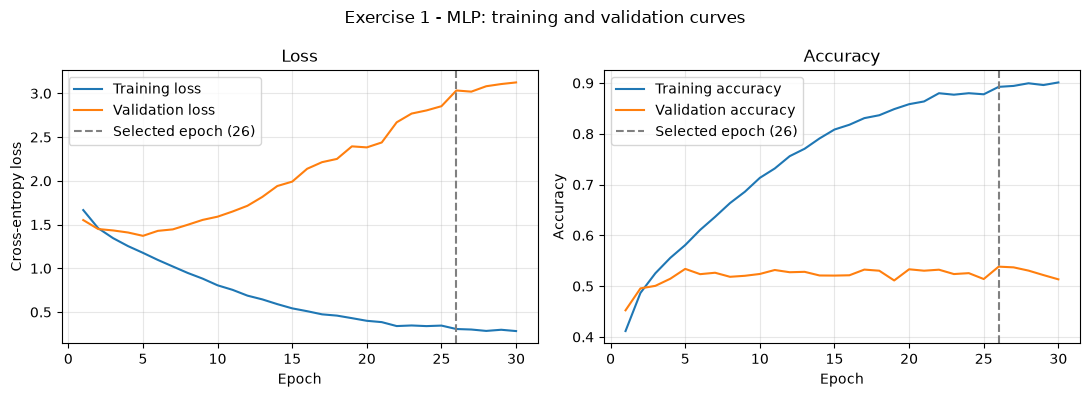

In [7]:
plot_history(history, best_epoch, "Exercise 1 - MLP: training and validation curves", "ex1_mlp_curves.png")

## 7. Final evaluation

The selected model is evaluated once on the clean training images, the validation set and the test set. The confusion matrix shows which classes the MLP mixes up.

Partition       Loss   Accuracy
train         0.2772     90.51%
val           3.0328     53.84%
test          2.9696     53.25%
Generalisation gap (train - test accuracy): 37.26 percentage points


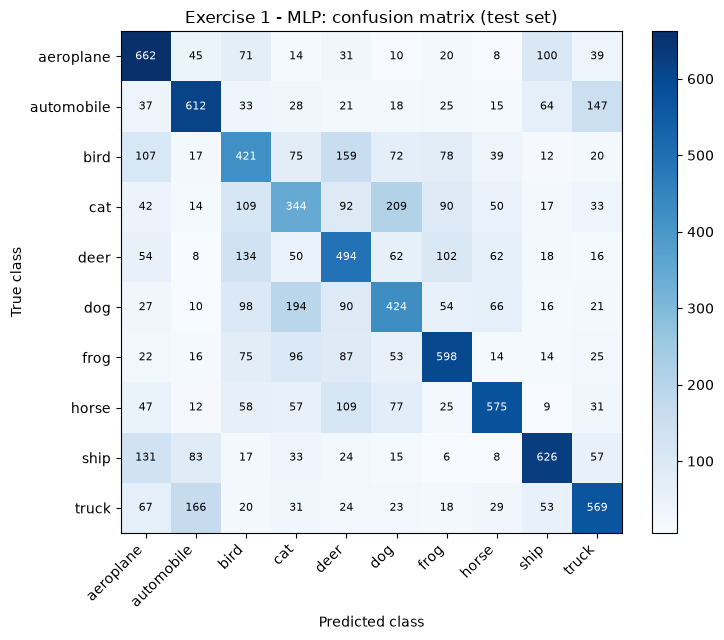


Per-class test accuracy:
  aeroplane   66.20%
  ship        62.60%
  automobile  61.20%
  frog        59.80%
  horse       57.50%
  truck       56.90%
  deer        49.40%
  dog         42.40%
  bird        42.10%
  cat         34.40%


In [8]:
final = final_evaluation(model, loaders)
print_final(final)

cm = plot_confusion_matrix(model, loaders["test"], "Exercise 1 - MLP: confusion matrix (test set)", "ex1_mlp_confusion.png")
per_class = cm.diagonal() / cm.sum(axis=1)
print("\nPer-class test accuracy:")
for name, acc in sorted(zip(CLASSES, per_class), key=lambda t: -t[1]):
    print(f"  {name:<11}{acc * 100:6.2f}%")

## 8. Save results

The numbers are stored in `results/ex1_mlp.json` so that the report and the later comparison with the CNN (Exercise 2) use exactly the values produced here.

In [9]:
save_results("ex1_mlp", {
    "experiment": "Exercise 1 - MLP",
    "model": "MLP 3072-1024-512-10 (ReLU)",
    "trainable_parameters": n_params,
    "best_epoch": best_epoch,
    "train_seconds": round(train_seconds, 1),
    "device": str(DEVICE),
    "config": {"seed": SEED, "val_size": VAL_SIZE, "batch_size": BATCH_SIZE, "epochs": EPOCHS,
               "learning_rate": LEARNING_RATE, "optimiser": "Adam", "loss": "CrossEntropyLoss"},
    "final": final,
    "history": history,
    "confusion_matrix_test": cm.tolist(),
})

Saved results\ex1_mlp.json
